# Mini Project: Student Pass Prediction using Logistic Regression
**Goal:** Predict whether a student passes using study hours, attendance, and previous score.

This is a learning project built with **synthetic data generated in the notebook**. It is not suitable for real student assessment.

### What you'll learn
- Create and explore a dataset
- Visualize class distribution, feature relationships, and correlations
- Split data and train Logistic Regression
- Evaluate using accuracy, precision, recall, F1-score, confusion matrix, and ROC-AUC
- Plot a probability-based decision boundary
- Predict a new example and save/load the model


In [1]:
# If needed, uncomment and run once:
# %pip install numpy pandas matplotlib seaborn scikit-learn joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve)
import joblib

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


## 1. Generate the dataset

In [2]:
n = 500
study_hours = np.clip(np.random.normal(4.5, 2.0, n), 0, 10)
attendance = np.clip(np.random.normal(78, 12, n), 35, 100)
previous_score = np.clip(np.random.normal(62, 15, n), 10, 100)

logit = -5.0 + 0.45*study_hours + 0.035*attendance + 0.025*previous_score
pass_probability = 1 / (1 + np.exp(-logit))
passed = np.random.binomial(1, pass_probability)

df = pd.DataFrame({
    "study_hours_per_day": study_hours.round(1),
    "attendance_percent": attendance.round(1),
    "previous_score": previous_score.round(1),
    "passed": passed
})
df["outcome"] = df["passed"].map({0: "Not Passed", 1: "Passed"})

print("Dataset shape:", df.shape)
display(df.head())
display(df.describe().round(2))
display(df["outcome"].value_counts().to_frame("count"))


Dataset shape: (500, 5)


,study_hours_per_day,attendance_percent,previous_score,passed,outcome
0,5.5,89.1,83.0,1,Passed
1,4.2,100.0,75.9,1,Passed
2,5.8,61.2,62.9,1,Passed
3,7.5,84.8,52.3,1,Passed
4,4.0,70.2,72.5,1,Passed


,study_hours_per_day,attendance_percent,previous_score,passed
count,500.00,500.00,500.00,500.00
mean,4.51,78.24,63.62,0.75
std,1.93,11.42,15.14,0.43
min,0.00,45.60,18.60,0.00
25%,3.10,70.88,52.98,0.00
50%,4.50,78.30,63.80,1.00
75%,5.80,85.82,73.32,1.00
max,10.00,100.00,100.00,1.00


,count
outcome,
Passed,374
Not Passed,126


## 2. Explore and visualize the data

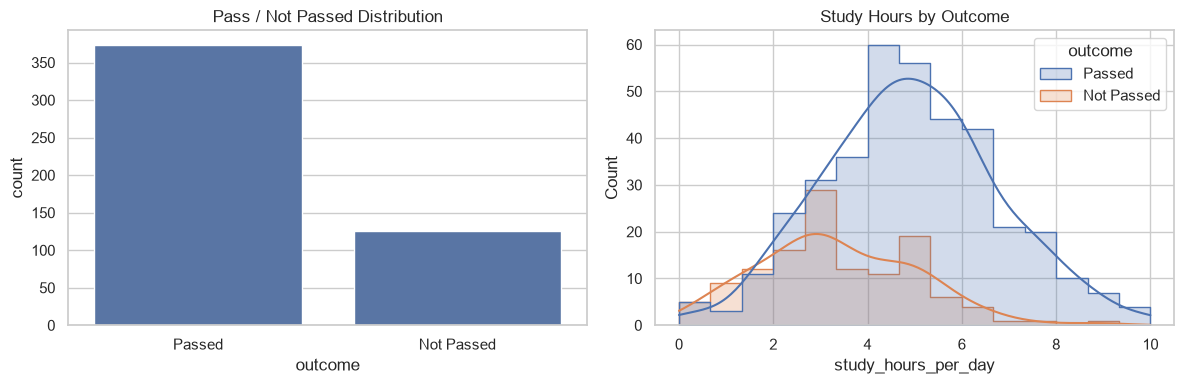

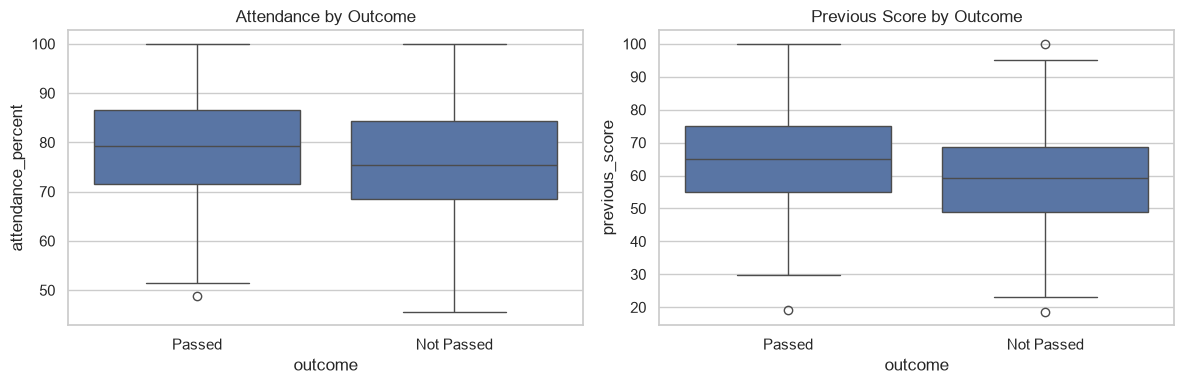

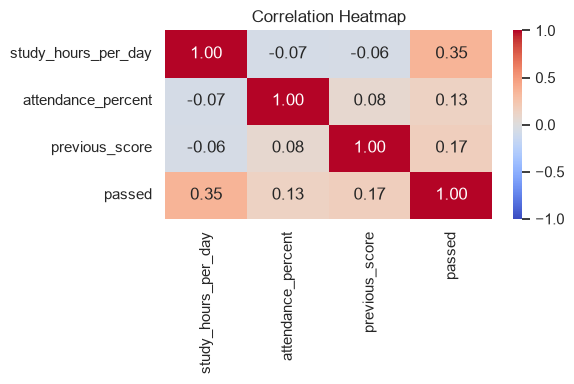

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="outcome", ax=axes[0])
axes[0].set_title("Pass / Not Passed Distribution")
sns.histplot(data=df, x="study_hours_per_day", hue="outcome",
             kde=True, element="step", ax=axes[1])
axes[1].set_title("Study Hours by Outcome")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="outcome", y="attendance_percent", ax=axes[0])
axes[0].set_title("Attendance by Outcome")
sns.boxplot(data=df, x="outcome", y="previous_score", ax=axes[1])
axes[1].set_title("Previous Score by Outcome")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
sns.heatmap(df[["study_hours_per_day", "attendance_percent",
                "previous_score", "passed"]].corr(),
            annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


## 3. Prepare training and testing data
`X` contains the input features; `y` contains the target label. The scaler is placed inside a pipeline so it learns scaling values only from training data.


In [4]:
features = ["study_hours_per_day", "attendance_percent", "previous_score"]
X = df[features]
y = df["passed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 400
Testing samples: 100


## 4. Train the Logistic Regression model

In [5]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
model.fit(X_train, y_train)
print("Training accuracy:", round(model.score(X_train, y_train), 3))
print("Testing accuracy:", round(model.score(X_test, y_test), 3))


Training accuracy: 0.78
Testing accuracy: 0.75


## 5. Evaluate the model

In [6]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}
display(pd.DataFrame(metrics.items(), columns=["Metric", "Score"]).style.format({"Score": "{:.3f}"}))
print(classification_report(y_test, y_pred,
      target_names=["Not Passed", "Passed"], zero_division=0))


,Metric,Score
0,Accuracy,0.750
1,Precision,0.791
2,Recall,0.907
3,F1-score,0.845
4,ROC-AUC,0.795


              precision    recall  f1-score   support

  Not Passed       0.50      0.28      0.36        25
      Passed       0.79      0.91      0.84        75

    accuracy                           0.75       100
   macro avg       0.65      0.59      0.60       100
weighted avg       0.72      0.75      0.72       100



## 6. Confusion matrix

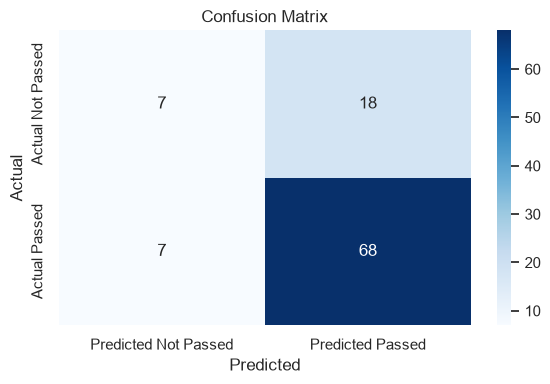

In [7]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted Not Passed", "Predicted Passed"],
            yticklabels=["Actual Not Passed", "Actual Passed"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


## 7. ROC curve

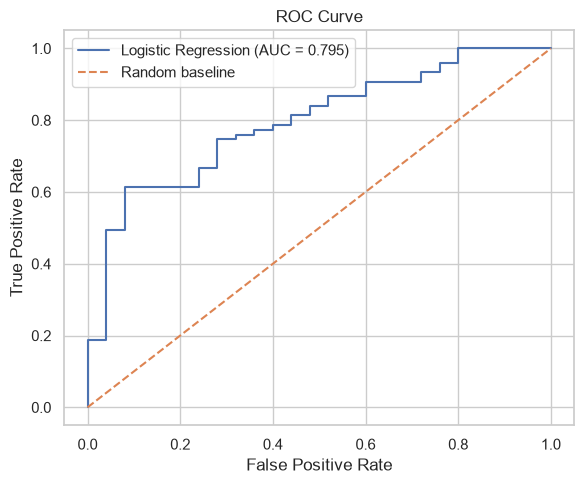

In [8]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()


## 8. Decision boundary visualization
This is a 2D slice of the three-feature model: previous score is held at its median while study hours and attendance vary.


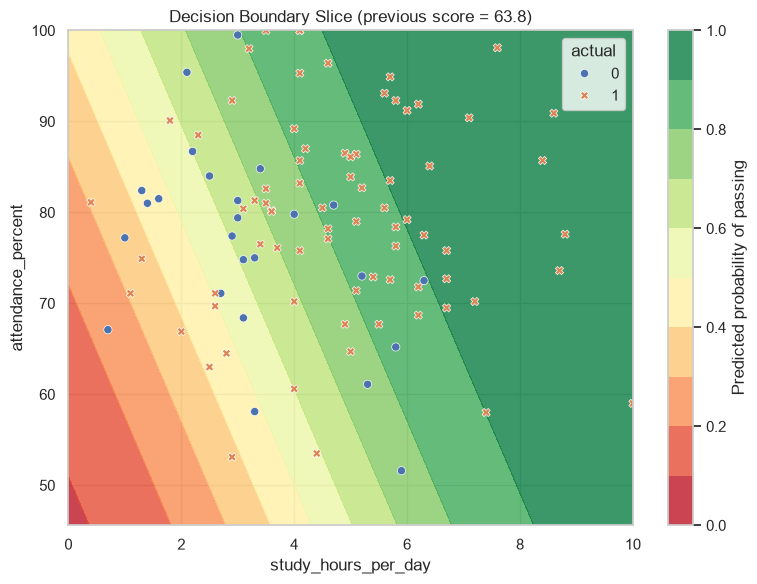

In [9]:
hours = np.linspace(X["study_hours_per_day"].min(), X["study_hours_per_day"].max(), 100)
att = np.linspace(X["attendance_percent"].min(), X["attendance_percent"].max(), 100)
HH, AA = np.meshgrid(hours, att)
fixed_score = X["previous_score"].median()
grid = pd.DataFrame({
    "study_hours_per_day": HH.ravel(),
    "attendance_percent": AA.ravel(),
    "previous_score": fixed_score
})
prob = model.predict_proba(grid)[:, 1].reshape(HH.shape)

plt.figure(figsize=(8, 6))
contour = plt.contourf(HH, AA, prob, levels=np.linspace(0, 1, 11), cmap="RdYlGn", alpha=0.8)
plt.colorbar(contour, label="Predicted probability of passing")
points = X_test.copy()
points["actual"] = y_test.values
sns.scatterplot(data=points, x="study_hours_per_day", y="attendance_percent",
                hue="actual", style="actual", s=35)
plt.title(f"Decision Boundary Slice (previous score = {fixed_score:.1f})")
plt.tight_layout()
plt.show()


## 9. Predict for a new example

In [10]:
new_student = pd.DataFrame([{
    "study_hours_per_day": 5.0,
    "attendance_percent": 82.0,
    "previous_score": 68.0
}])
pred = model.predict(new_student)[0]
prob = model.predict_proba(new_student)[0, 1]
print("Predicted outcome:", "Passed" if pred == 1 else "Not Passed")
print(f"Estimated pass probability: {prob:.1%}")


Predicted outcome: Passed
Estimated pass probability: 87.2%


## 10. Save and reload the model

In [11]:
joblib.dump(model, "student_pass_logistic_regression.joblib")
loaded_model = joblib.load("student_pass_logistic_regression.joblib")
print("Model saved and reloaded.")
print("Reloaded prediction:", loaded_model.predict(new_student)[0])


Model saved and reloaded.
Reloaded prediction: 1


## 11. Practice tasks
1. Change `test_size` from `0.20` to `0.30`.
2. Try `C=0.1`, `C=1.0`, and `C=10` in Logistic Regression.
3. Compare precision and recall at thresholds 0.4, 0.5, and 0.6.
4. Add a feature such as sleep hours to the generated dataset.
5. Compare this model with a Decision Tree or Random Forest.

## Conclusion
You built a complete binary-classification workflow. Since the dataset is synthetic, its scores demonstrate the process rather than real-world predictive performance.
